# 05. Robustness: slower models, other targets, unseen cancer types, another assay

All on the **focus panel**: 36 drugs fixed by a rule before any model was evaluated (the 30 drugs
shared with GDSC1 whose response varies most, plus 6 drugs with well-known biomarkers;
`drugresponse.panel`).

In [1]:
import sys, warnings, pickle
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
T = ROOT / "outputs" / "tables"; FIG = ROOT / "outputs" / "figures"
from drugresponse import data

In [2]:
panel = pd.read_csv(T / "panel_summary.csv", index_col=0)
panel.round(3)

,n_drugs,median_r,median_r2,median_rho_within,share_r_above_0_3,median_gain_vs_tissue,share_beats_tissue,wilcoxon_p_vs_tissue
model,,,,,,,,
Adaptive lasso,36,0.533,0.240,0.260,0.917,0.109,0.917,0.0
Elastic net,36,0.564,0.317,0.276,0.944,0.133,0.972,0.0
Group lasso,36,0.569,0.324,0.230,0.917,0.126,1.000,0.0
Lasso,36,0.562,0.315,0.271,0.944,0.133,0.972,0.0
Mean,36,-0.044,-0.001,NaN,0.000,-0.468,0.000,0.0
PCR,36,0.557,0.305,0.253,0.944,0.117,1.000,0.0
Ridge,36,0.586,0.344,0.287,0.944,0.143,1.000,0.0
Tissue,36,0.426,0.179,NaN,0.833,NaN,NaN,NaN


## Gene-filter size and response measure
The main analysis keeps the 2,000 most variable genes, a number fixed for compute, not tuned. Here
1,000 and 5,000 are compared, and ln(IC50) replaces AUC as the response.

In [3]:
pd.read_csv(T / 'sensitivity.csv')

,design,model,r,rho_within
0,genes_1000,Lasso,0.553,0.260
1,genes_1000,Ridge,0.575,0.280
2,genes_2000 (main),Lasso,0.562,0.271
3,genes_2000 (main),Ridge,0.586,0.287
4,genes_2000 (main),Tissue,0.426,NaN
5,genes_5000,Lasso,0.587,0.329
6,genes_5000,Ridge,0.598,0.319
7,target_ln_ic50,Lasso,0.597,0.351
8,target_ln_ic50,Ridge,0.616,0.390
9,target_ln_ic50,Tissue,0.452,NaN


## Leave one cancer type out
Train on every other tissue, predict the held-out one. Two things can fail: the **level** (an unseen
tissue's average sensitivity cannot be learned from a tissue indicator) and the **ranking** within it.

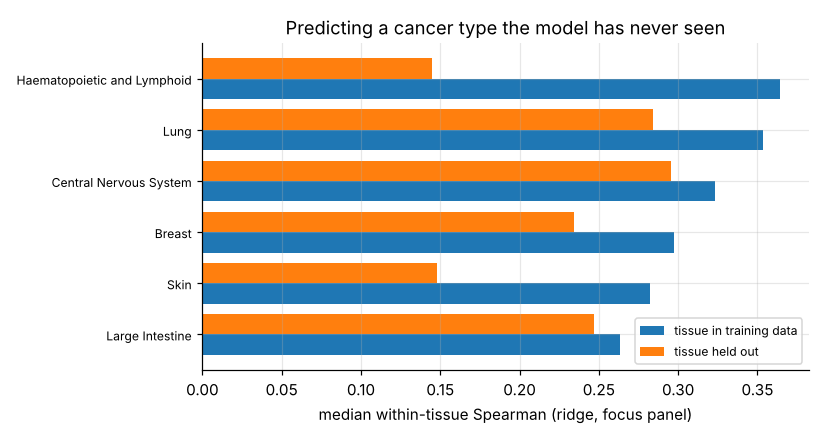

,tissue,model,rho_seen,rho_unseen,bias_seen,bias_unseen
0,Breast,Lasso,0.264,0.168,-0.003,-0.019
1,Breast,Ridge,0.297,0.234,-0.002,-0.011
2,Central Nervous System,Lasso,0.317,0.280,-0.001,-0.003
3,Central Nervous System,Ridge,0.323,0.295,-0.001,-0.006
4,Haematopoietic and Lymphoid,Lasso,0.321,0.145,0.003,0.093
5,Haematopoietic and Lymphoid,Ridge,0.364,0.144,0.002,0.069
6,Large Intestine,Lasso,0.232,0.216,0.004,0.005
7,Large Intestine,Ridge,0.264,0.247,0.002,0.001
8,Lung,Lasso,0.352,0.319,-0.003,-0.006
9,Lung,Ridge,0.354,0.284,-0.002,-0.003


In [4]:
display(Image(FIG / 'leave_tissue_out.png'))
pd.read_csv(T / 'leave_tissue_out.csv')

## Cross-assay: GDSC2-trained models scored against GDSC1
Many drugs were screened twice by Sanger with different viability assays (GDSC1: Syto60 /
resazurin; GDSC2: CellTiter-Glo). A model trained on GDSC2 cannot be expected to agree with GDSC1
better than the two assays agree with each other, so their agreement (`r_assays`) is the ceiling.

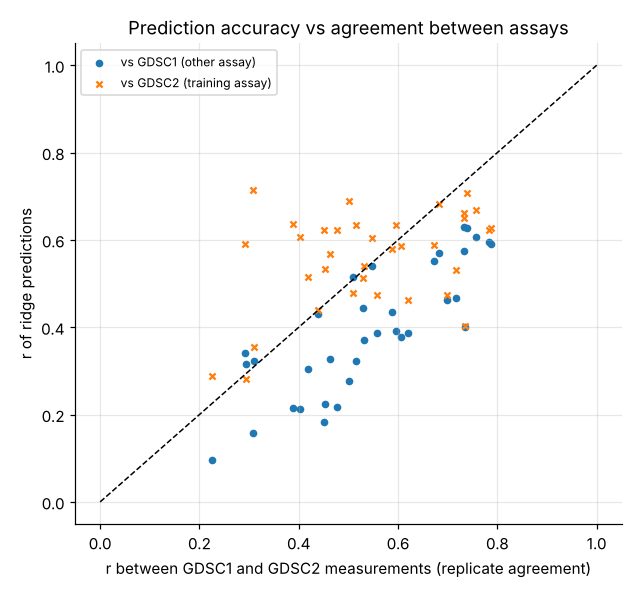

,model,r_gdsc2,r_gdsc1,r_assays
0,Lasso,0.562,0.380,0.531
1,Ridge,0.589,0.387,0.531
2,Tissue,0.425,0.255,0.531


In [5]:
display(Image(FIG / 'cross_assay.png'))
pd.read_csv(T / 'cross_assay.csv')

In [6]:
ca = pd.read_csv(T / "cross_assay_by_drug.csv")
ca[ca.model == "Ridge"].sort_values("r_assays", ascending=False)[["drug_name", "n", "r_assays", "r_gdsc2", "r_gdsc1"]].round(3)

,drug_name,n,r_assays,r_gdsc2,r_gdsc1
10,Navitoclax,900,0.787,0.628,0.592
70,Dabrafenib,818,0.783,0.622,0.595
40,Selumetinib,861,0.757,0.669,0.606
67,Trametinib,850,0.739,0.707,0.627
88,AZD5582,801,0.736,0.402,0.401
31,Nutlin-3a (-),905,0.734,0.661,0.574
13,Refametinib,866,0.734,0.651,0.629
43,Dasatinib,383,0.717,0.531,0.467
28,Afatinib,899,0.699,0.474,0.463
37,PD0325901,890,0.683,0.681,0.570


## Independent lab: the Broad Institute's PRISM screen
PRISM (Corsello et al., 2020) screened pooled, DNA-barcoded cell lines: a different lab, assay,
plate format and dose range. The GDSC2 models are not retrained. Each line's out-of-fold
prediction, from a model that never saw that line, is compared with PRISM's AUC for the same drug.
Only lines whose identity passed DNA fingerprinting (STR profiling) are used, and drugs are matched
by name.

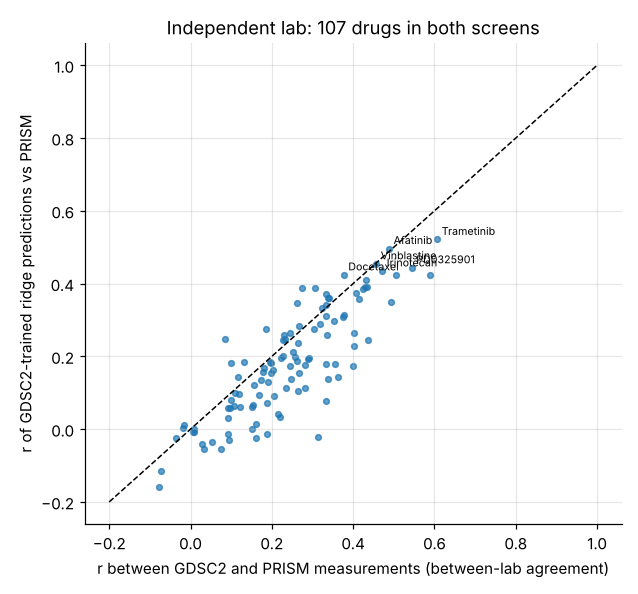

,n,r_gdsc2,r_prism,r_assays,n_drugs
model,,,,,
Elastic net,279.0,0.291,0.145,0.243,107
Lasso,279.0,0.285,0.140,0.243,107
Ridge,279.0,0.343,0.180,0.243,107
Tissue,279.0,0.201,0.094,0.243,107


In [7]:
display(Image(FIG / 'prism.png'))
pd.read_csv(T / 'prism.csv', index_col=0)

In [8]:
sc = pd.read_csv(T / "prism_by_drug.csv")
r = sc[sc.model == "Ridge"]
print(f"{len(r)} drugs; ridge reaches a median {(r.r_prism / r.r_assays).median():.0%} of the between-lab agreement;"
      f" correlation across drugs between agreement and ridge accuracy: {r[['r_assays', 'r_prism']].corr().iloc[0, 1]:.2f}")
r.sort_values("r_assays", ascending=False)[["drug_name", "n", "r_assays", "r_gdsc2", "r_prism"]].head(10).round(3)

107 drugs; ridge reaches a median 77% of the between-lab agreement; correlation across drugs between agreement and ridge accuracy: 0.85


,drug_name,n,r_assays,r_gdsc2,r_prism
222,Trametinib,341,0.607,0.663,0.521
138,Dasatinib,320,0.589,0.564,0.423
122,PD0325901,317,0.544,0.691,0.443
330,Topotecan,274,0.506,0.567,0.422
226,Dabrafenib,272,0.492,0.654,0.351
86,Afatinib,315,0.488,0.421,0.496
158,Irinotecan,327,0.471,0.584,0.435
6,Vinblastine,283,0.457,0.509,0.454
26,Gefitinib,279,0.437,0.364,0.246
382,Osimertinib,319,0.434,0.382,0.390


The two labs agree much less than Sanger's two assays do. Where they agree, as for MEK, BRAF, EGFR and TOP1
inhibitors, GDSC-trained predictions carry over. Where they barely agree, no model trained on one lab
can predict the other. The ceiling is set by measurement, not by the choice of penalty.